
Dataset downloaded successfully!
Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2021-11-04  147.242020  148.675801  146.929894  147.846745  60394600
2021-11-05  147.769501  148.668150  146.577810  148.365346  65463900
2021-11-08  146.948975  148.052757  146.675473  147.896467  55020900
2021-11-09  147.310379  147.915987  146.577783  146.714534  56787900
2021-11-10  144.487457  146.646180  144.419089  146.538732  65187100

Missing values: 0


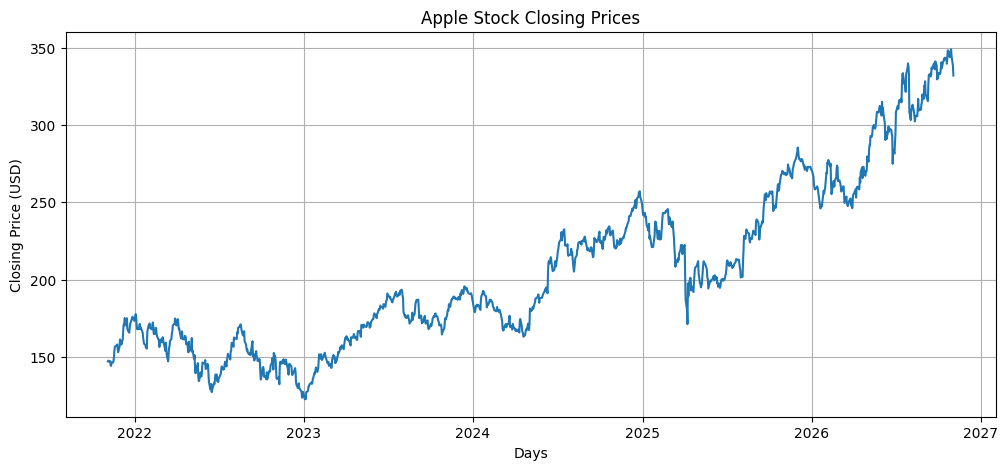


Input shape: (1194, 60, 1)
Output shape: (1194,)

Training samples: 955
Testing samples: 239


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - loss: 0.0108 - val_loss: 0.0018
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - loss: 0.0023 - val_loss: 0.0011
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 0.0018 - val_loss: 0.0015
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.0017 - val_loss: 0.0013
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0018 - val_loss: 0.0013
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 0.0016 - val_loss: 0.0013
Epoch 7/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - loss: 0.0018 - val_loss: 0.0011
Epoch 8/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0018 - val_loss: 0.0019
Epoch 9/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - loss: 0.0016 - val_loss: 0.0012
Epoch 10/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 11/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - loss: 0.0013 - val_loss: 0.0011
Epoch 12/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 

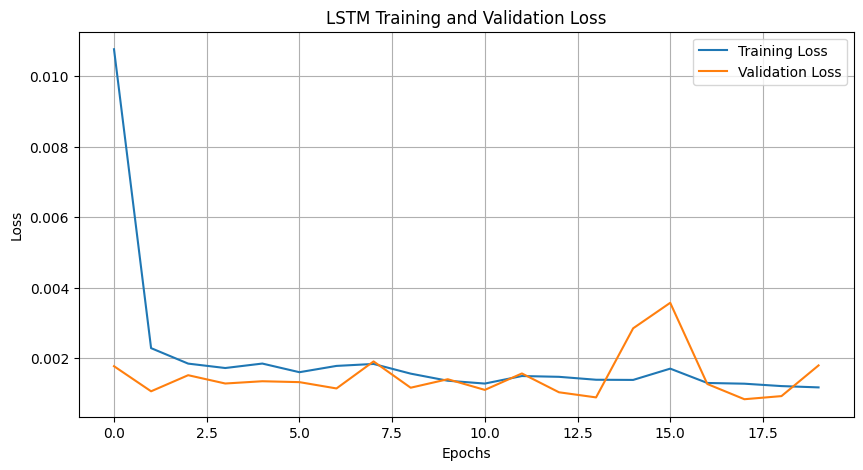

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 159ms/step

========== MODEL EVALUATION ==========
Mean Squared Error (MSE): 203.5537
Mean Absolute Error (MAE): 12.1549
Root Mean Squared Error (RMSE): 14.2672


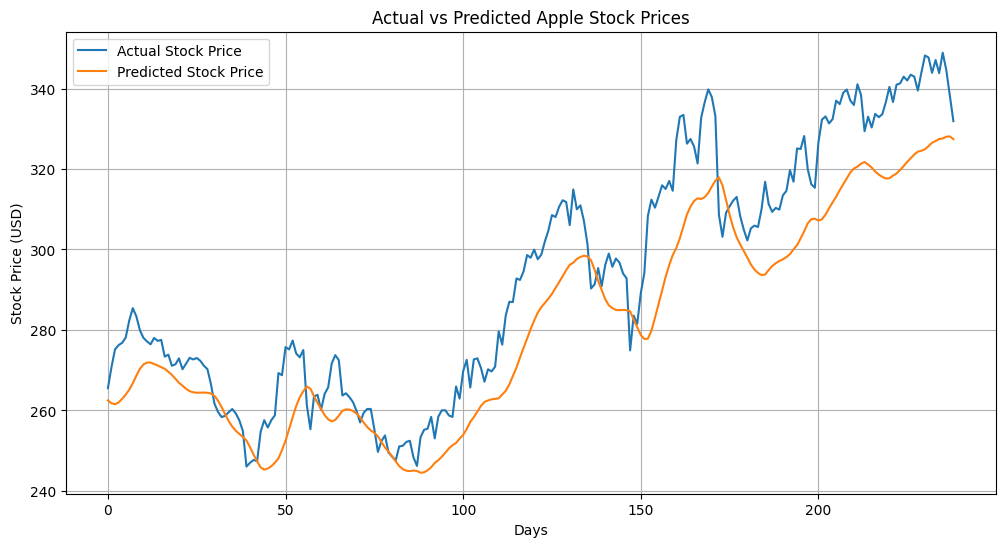

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step

========== NEXT DAY PREDICTION ==========
Predicted next day's closing price: $ 325.79

========== FILES SAVED SUCCESSFULLY ==========
1. stock_dataset.csv
2. lstm_stock_model.keras
3. prediction_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Assignment completed successfully!


In [1]:

# ============================================================
# ASSIGNMENT 4: LSTM-BASED STOCK PRICE FORECASTING
# Dataset: Apple (AAPL) Historical Stock Prices
# Algorithm: Long Short-Term Memory (LSTM)
# Platform: Google Colab
# ============================================================

# 1. INSTALL AND IMPORT LIBRARIES

!pip install yfinance -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout


# 2. DOWNLOAD STOCK PRICE DATASET

print("Downloading Apple stock dataset...")

stock_data = yf.download(
    "AAPL",
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

# Save original dataset as CSV
stock_data.to_csv("stock_dataset.csv")

print("\nDataset downloaded successfully!")
print(stock_data.head())


# 3. DATA PREPROCESSING

# Select closing price column
data = stock_data[['Close']].copy()

# Remove missing values
data.dropna(inplace=True)

print("\nMissing values:", data.isnull().sum().sum())


# 4. VISUALIZE HISTORICAL STOCK PRICES

plt.figure(figsize=(12, 5))
plt.plot(data['Close'])

plt.title("Apple Stock Closing Prices")
plt.xlabel("Days")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.show()


# 5. NORMALIZE THE DATASET

# Scale values between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)


# 6. CREATE SEQUENCES FOR LSTM

# Use previous 60 days to predict next day's price
time_step = 60

X = []
y = []

for i in range(time_step, len(scaled_data)):

    # Previous 60 days as input
    X.append(scaled_data[i-time_step:i, 0])

    # Next day's closing price as target
    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)

# Reshape data into LSTM format:
# Samples, Time Steps, Features
X = X.reshape(X.shape[0], X.shape[1], 1)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)


# 7. SPLIT DATA INTO TRAINING AND TESTING SETS

# Maintain chronological order
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# 8. BUILD LSTM MODEL

model = Sequential()

# First LSTM layer
model.add(LSTM(
    50,
    return_sequences=True,
    input_shape=(X_train.shape[1], 1)
))

# Dropout to reduce overfitting
model.add(Dropout(0.2))

# Second LSTM layer
model.add(LSTM(50, return_sequences=False))

# Another dropout layer
model.add(Dropout(0.2))

# Output layer for stock price prediction
model.add(Dense(1))

# Compile model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Display model structure
model.summary()


# 9. TRAIN THE LSTM MODEL

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

print("\nModel training completed!")


# 10. VISUALIZE TRAINING LOSS

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()


# 11. MAKE PREDICTIONS

predictions = model.predict(X_test)

# Convert normalized predictions into actual prices
predicted_prices = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)


# 12. EVALUATE MODEL PERFORMANCE

mse = mean_squared_error(actual_prices, predicted_prices)

mae = mean_absolute_error(actual_prices, predicted_prices)

rmse = np.sqrt(mse)

print("\n========== MODEL EVALUATION ==========")

print("Mean Squared Error (MSE):", round(mse, 4))
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))


# 13. VISUALIZE ACTUAL VS PREDICTED PRICES

plt.figure(figsize=(12, 6))

plt.plot(actual_prices, label='Actual Stock Price')
plt.plot(predicted_prices, label='Predicted Stock Price')

plt.title("Actual vs Predicted Apple Stock Prices")
plt.xlabel("Days")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.grid(True)
plt.show()


# 14. PREDICT NEXT DAY'S CLOSING PRICE

# Select the latest 60 days
last_60_days = scaled_data[-60:]

# Reshape input for LSTM
last_60_days = last_60_days.reshape(1, 60, 1)

# Predict next day's price
next_day_prediction = model.predict(last_60_days)

# Convert prediction to original scale
next_day_price = scaler.inverse_transform(
    next_day_prediction
)

print("\n========== NEXT DAY PREDICTION ==========")

print(
    "Predicted next day's closing price: $",
    round(float(next_day_price[0][0]), 2)
)


# 15. SAVE TRAINED MODEL AND RESULTS

# Save trained model
model.save("lstm_stock_model.keras")

# Save actual and predicted prices
results = pd.DataFrame({
    'Actual Price': actual_prices.flatten(),
    'Predicted Price': predicted_prices.flatten()
})

results.to_csv("prediction_results.csv", index=False)

print("\n========== FILES SAVED SUCCESSFULLY ==========")
print("1. stock_dataset.csv")
print("2. lstm_stock_model.keras")
print("3. prediction_results.csv")

# Download dataset and results from Google Colab
from google.colab import files

files.download("stock_dataset.csv")
files.download("prediction_results.csv")
files.download("lstm_stock_model.keras")

print("\nAssignment completed successfully!")
